In [1]:
import numpy as np
from operators import stretch, shear, reflection, rotation, rotate_xy, rotate_yz, rotate_xz
from viz import plot_shape, plot_points
from composition import apply_sequence
from off_reader import read_off, sample_points

In [ ]:
lynx = np.array([
    [209.70, 368.42], [157.63, 332.16], [118.82, 284.21], [80.95, 224.56], [43.08, 244.44],
    [20.36, 266.67], [-4.26, 293.57], [2.37, 263.16], [-20.36, 292.40], [-39.29, 299.42],
    [-21.30, 259.65], [-50.65, 267.84], [-39.29, 242.11], [-55.38, 240.94], [-100.83, 300.58],
    [-149.11, 345.03], [-172.78, 361.40], [-189.82, 300.58], [-192.66, 225.73], [-181.30, 145.03],
    [-168.05, 104.09], [-184.14, 66.67], [-186.98, 31.58], [-183.20, 3.51], [-208.76, -4.68],
    [-197.40, -29.24], [-182.25, -44.44], [-203.08, -43.27], [-172.78, -92.40], [-131.12, -126.32],
    [-101.78, -147.37], [-74.32, -163.74], [-110.30, -224.56], [-143.43, -287.72], [-161.42, -240.94],
    [-282.60, -221.05], [-388.64, -205.85], [-370.65, -301.75], [-339.41, -397.66], [18.46, -397.66],
    [345.09, -400.00], [359.29, -378.95], [367.81, -342.69], [346.98, -362.57], [363.08, -302.92],
    [357.40, -243.27], [348.88, -266.67], [336.57, -201.17], [290.18, -135.67], [240.00, -118.13],
    [258.93, -164.91], [257.99, -228.07], [252.31, -271.35], [256.09, -333.33], [247.57, -359.06],
    [230.53, -307.60], [194.56, -238.60], [160.47, -181.29], [120.71, -149.71], [165.21, -132.16],
    [201.18, -100.58], [183.20, -99.42], [221.07, -73.68], [253.25, -24.56], [222.01, -23.39],
    [251.36, -1.17], [262.72, 24.56], [234.32, 25.73], [214.44, 42.11], [202.13, 60.82],
    [220.12, 101.75], [234.32, 160.23], [240.00, 230.41], [232.43, 316.96]
])

L = lynx.T

Stretch (1.5, 0.7)
[[1.5 0. ]
 [0.  0.7]]


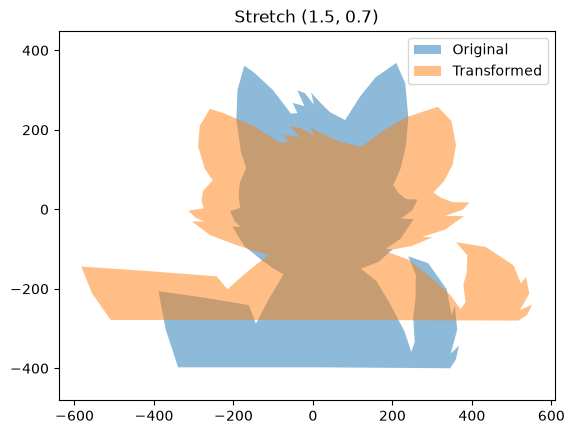

Shear (0.5, 0)
[[1.  0.5]
 [0.  1. ]]


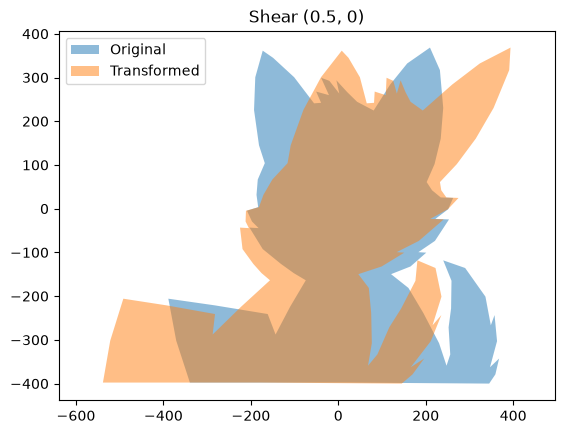

Reflection (line y = x)
[[0. 1.]
 [1. 0.]]


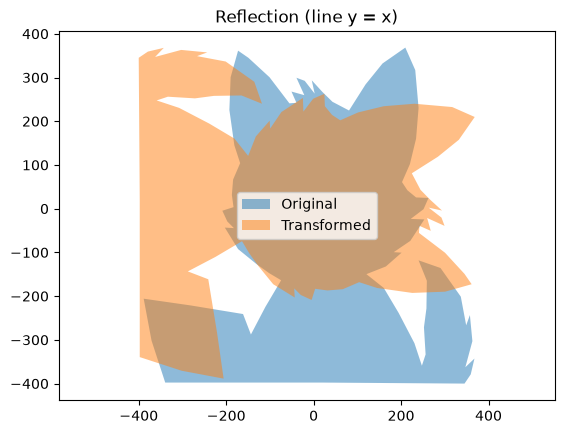

Rotation (45°)
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


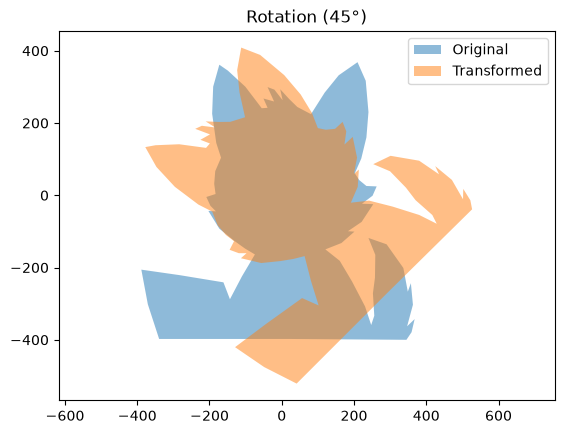

In [ ]:
result, A = stretch(L, 1.5, 0.7)
plot_shape(L, result, A, "Stretch (1.5, 0.7)")

result, A = shear(L, 0.5, 0)
plot_shape(L, result, A, "Shear (0.5, 0)")

result, A = reflection(L, 1, 1)
plot_shape(L, result, A, "Reflection (line y = x)")

result, A = rotation(L, np.radians(45))
plot_shape(L, result, A, "Rotation (45°)")

In [ ]:
from composition import apply_sequence

In [ ]:
S = ("Stretch (1.5, 0.7)", stretch, (1.5, 0.7))
H = ("Shear (0.5, 0)", shear, (0.5, 0))
R = ("Rotation (45°)", rotation, (np.radians(45),))

Stretch (1.5, 0.7)
[[1.5 0. ]
 [0.  0.7]]


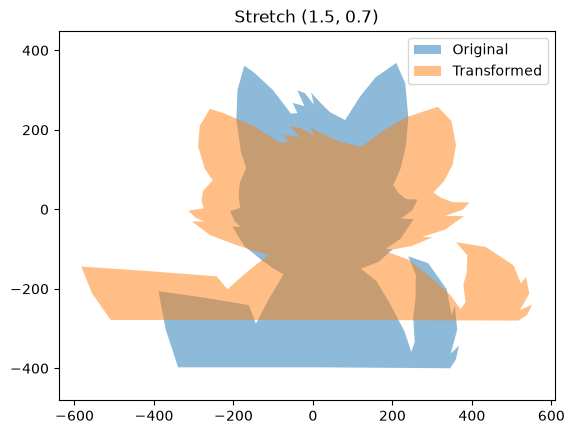

Shear (0.5, 0)
[[1.  0.5]
 [0.  1. ]]


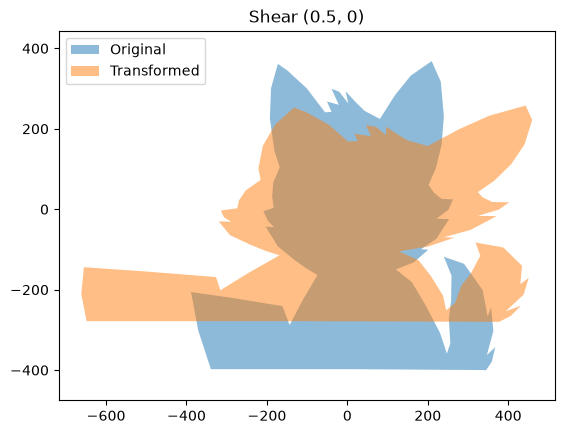

Rotation (45°)
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


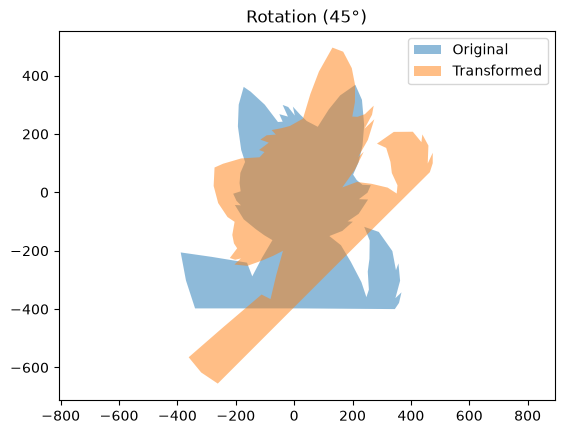

Total: Stretch (1.5, 0.7) → Shear (0.5, 0) → Rotation (45°)
[[ 1.06066017 -0.24748737]
 [ 1.06066017  0.74246212]]


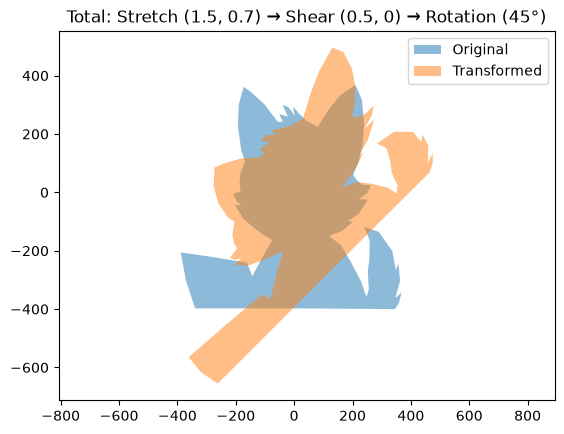

In [ ]:
result_1, total_1 = apply_sequence(L, [S, H, R])

Rotation (45°)
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


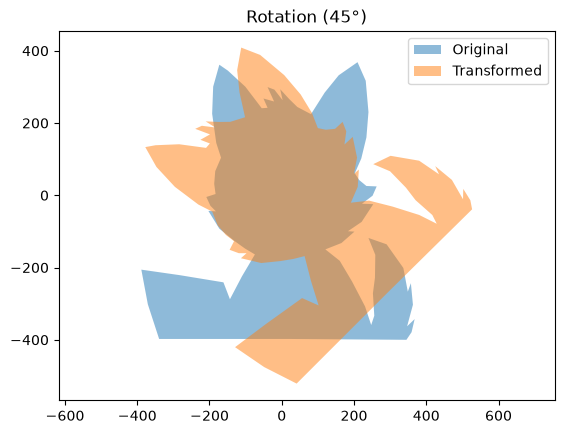

Shear (0.5, 0)
[[1.  0.5]
 [0.  1. ]]


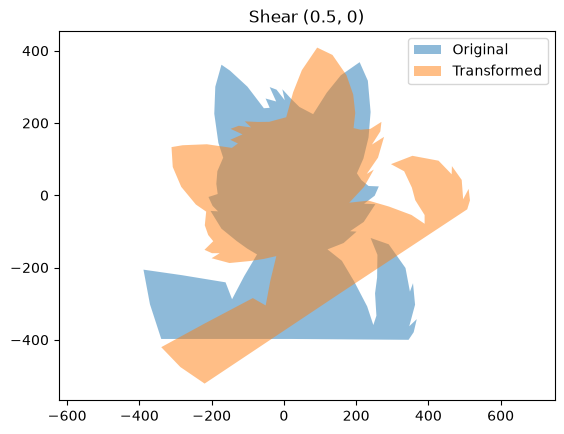

Stretch (1.5, 0.7)
[[1.5 0. ]
 [0.  0.7]]


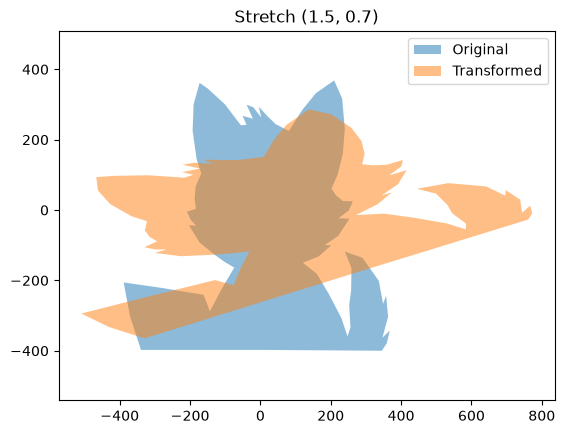

Total: Rotation (45°) → Shear (0.5, 0) → Stretch (1.5, 0.7)
[[ 1.59099026 -0.53033009]
 [ 0.49497475  0.49497475]]


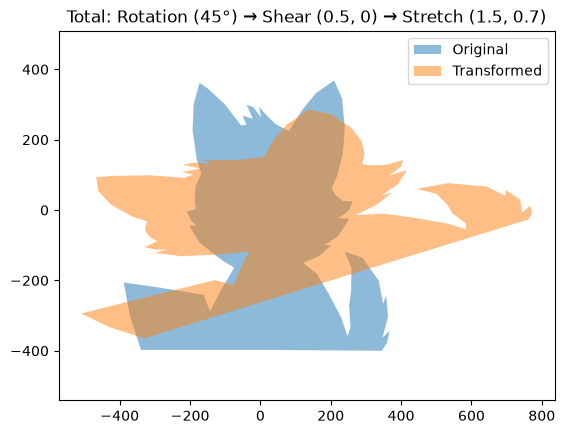

In [ ]:
result_2, total_2 = apply_sequence(L, [R, H, S])

Shear (0.5, 0)
[[1.  0.5]
 [0.  1. ]]


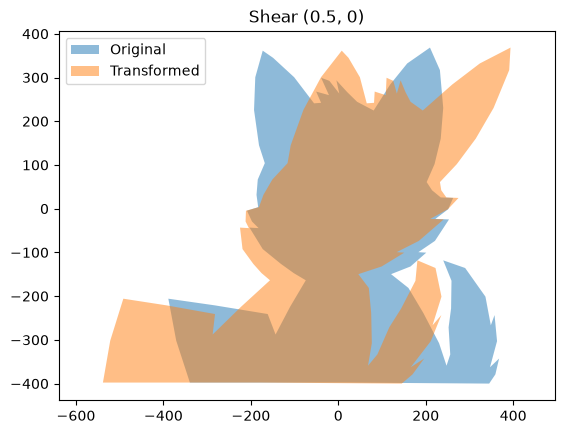

Stretch (1.5, 0.7)
[[1.5 0. ]
 [0.  0.7]]


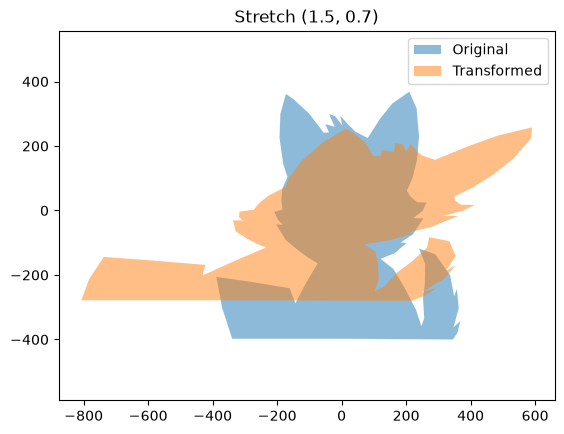

Rotation (45°)
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


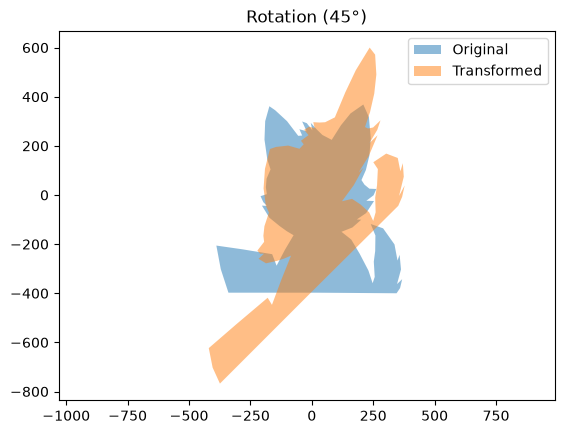

Total: Shear (0.5, 0) → Stretch (1.5, 0.7) → Rotation (45°)
[[1.06066017 0.03535534]
 [1.06066017 1.02530483]]


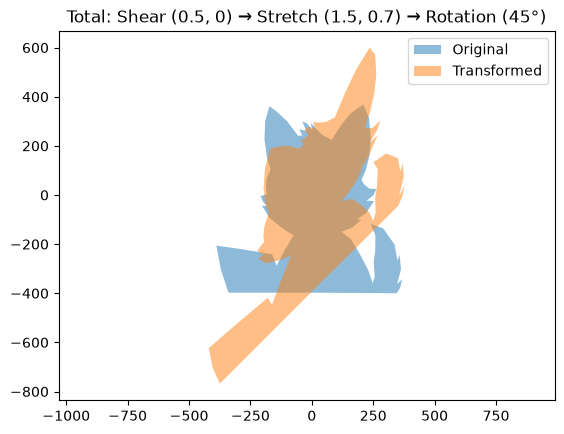

In [ ]:
result_3, total_3 = apply_sequence(L, [H, S, R])

(53432, 3)
Original
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


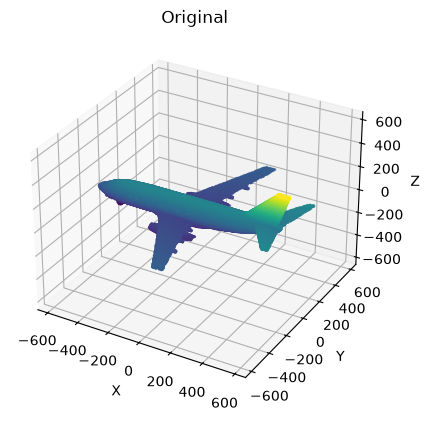

In [ ]:
vertices, faces = read_off(r"ModelNet40\airplane\test\airplane_0725.off")  
print(vertices.shape)

V = sample_points(vertices, faces).T
V = V - V.mean(axis=1, keepdims=True)  # move to the center

plot_points(V, np.eye(3), "Original")

45° in xy plane (about z-axis)
[[ 0.70710678 -0.70710678  0.        ]
 [ 0.70710678  0.70710678  0.        ]
 [ 0.          0.          1.        ]]


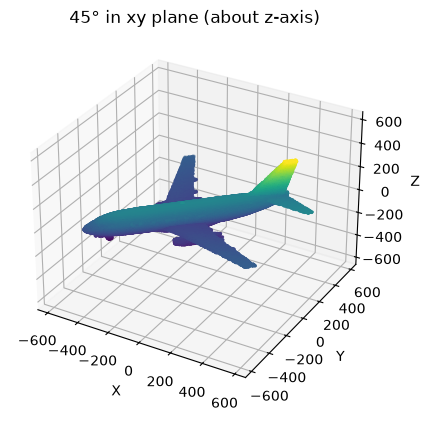

45° in yz plane (about x-axis)
[[ 1.          0.          0.        ]
 [ 0.          0.70710678 -0.70710678]
 [ 0.          0.70710678  0.70710678]]


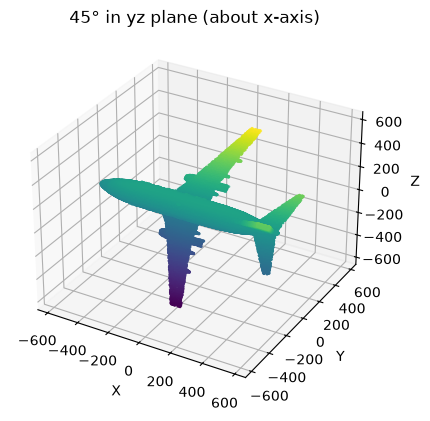

45° in xz plane (about y-axis)
[[ 0.70710678  0.         -0.70710678]
 [ 0.          1.          0.        ]
 [ 0.70710678  0.          0.70710678]]


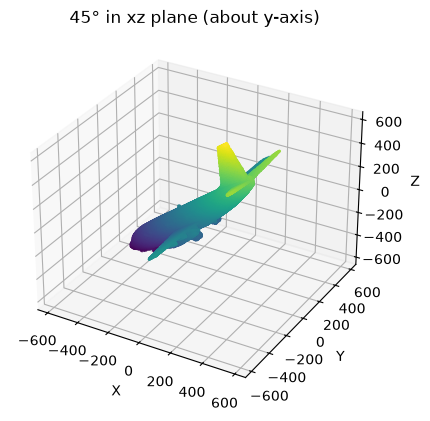

In [7]:
theta = np.radians(45)

result, A = rotate_xy(V, theta)
plot_points(result, A, "45° in xy plane (about z-axis)")

result, A = rotate_yz(V, theta)
plot_points(result, A, "45° in yz plane (about x-axis)")

result, A = rotate_xz(V, theta)
plot_points(result, A, "45° in xz plane (about y-axis)")

Rotations: xy (30°) → yz (45°) → xz (60°)
[[ 0.12682648 -0.78033009 -0.61237244]
 [ 0.35355339  0.61237244 -0.70710678]
 [ 0.9267767  -0.12682648  0.35355339]]


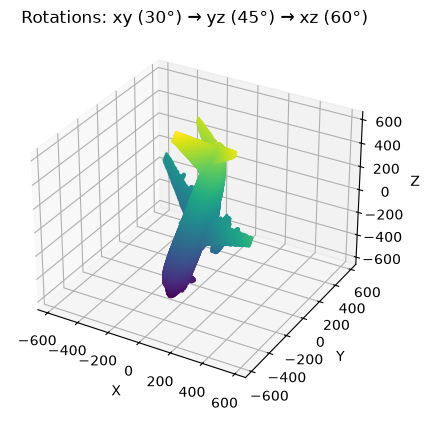

In [8]:
result_1, A_xy = rotate_xy(V, np.radians(30))
result_2, A_yz = rotate_yz(result_1, np.radians(45))
result_3, A_xz = rotate_xz(result_2, np.radians(60))

total = A_xz @ A_yz @ A_xy 
plot_points(result_3, total, "Rotations: xy (30°) → yz (45°) → xz (60°)")